# 04. Cohort Analysis and Retention

This notebook answers: once households start buying, how consistently do
they stay active from one period to the next, and does that differ by when
they started?

**What "retention" means here:** dunnhumby is a panel of 2,500 households
that the data provider tracked over two years. It is not the retailer's full
customer base, and households who stopped shopping entirely may simply not
be in the panel. So the retention matrix below measures the share of a
cohort that is active in each 28-day period, within this panel. It can say
whether panel households buy steadily or drift away, but not what share of
the retailer's customers churn.

**Methodological note on "months":** dunnhumby has no real calendar dates,
only `DAY` (1-711) and `WEEK_NO` (1-102). Cohorts are therefore built on
**28-day periods** (4-week blocks), not calendar months, chosen for
consistency with `WEEK_NO` (already validated in `01_data_setup_and_loading.ipynb`,
Section 3.4) rather than introducing an unverified new time unit. These are
referred to as "periods" throughout this notebook, not "months", to avoid
implying alignment with real calendar months that doesn't exist. Over 711
days, this yields 25 full periods plus a short 26th one (11 days).

**Consistency with prior notebooks:** a household's cohort is assigned based
on their first period with a genuine purchase (`sales_value > 0`), following
the same exclusion rule already established for Recency in
`02_rfm.ipynb`, a period where a household only had a return recorded
shouldn't count as when they "started" buying.

A household is considered **retained** (active) in a given period if it has at least
one basket with `sales_value > 0` in that period, regardless of how many.

## 1. Environment Setup and Cohort Assignment

We connect to PostgreSQL and compute, directly in SQL, each household's
28-day period number for every transaction, plus their cohort (the period
of their first genuine purchase). The cell also fails fast if a required `.env` variable is missing or `transaction_data` turns out to be empty, rather than surfacing a confusing SQL error later.

In [1]:
import os

import pandas as pd
from dotenv import load_dotenv
from scipy import stats
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

import matplotlib.pyplot as plt

load_dotenv()

DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")
DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")

required = {"DB_HOST": DB_HOST, "DB_PORT": DB_PORT, "DB_NAME": DB_NAME,
            "DB_USER": DB_USER, "DB_PASSWORD": DB_PASSWORD}
missing = [name for name, value in required.items() if not value]
if missing:
    raise EnvironmentError(f"Missing variables in .env: {missing}")

engine = create_engine(
    URL.create(
        drivername="postgresql+psycopg2",
        username=DB_USER,
        password=DB_PASSWORD,
        host=DB_HOST,
        port=int(DB_PORT),
        database=DB_NAME,
    )
)

with engine.connect() as conn:
    n_transactions = conn.execute(text("SELECT COUNT(*) FROM transaction_data")).scalar()
if n_transactions == 0:
    raise RuntimeError(
        "transaction_data is empty. Run 01_data_setup_and_loading.ipynb before this notebook."
    )

cohort_query = """
WITH genuine_transactions AS (
    SELECT
        household_key,
        basket_id,
        day,
        ((day - 1) / 28) + 1 AS period_no
    FROM transaction_data
    WHERE sales_value > 0
),
household_cohort AS (
    SELECT
        household_key,
        MIN(period_no) AS cohort_period
    FROM genuine_transactions
    GROUP BY household_key
),
household_activity AS (
    SELECT DISTINCT
        household_key,
        period_no
    FROM genuine_transactions
)
SELECT
    a.household_key,
    c.cohort_period,
    a.period_no AS active_period,
    a.period_no - c.cohort_period AS periods_since_cohort
FROM household_activity a
JOIN household_cohort c ON a.household_key = c.household_key
ORDER BY c.cohort_period, a.household_key, a.period_no;
"""

cohort_activity = pd.read_sql(text(cohort_query), engine)
print(f"Rows: {len(cohort_activity)}")
print(f"Distinct households: {cohort_activity['household_key'].nunique()}")
print(f"Cohort periods range: {cohort_activity['cohort_period'].min()} to {cohort_activity['cohort_period'].max()}")
cohort_activity.head(10)

Rows: 48396
Distinct households: 2500
Cohort periods range: 1 to 24


,household_key,cohort_period,active_period,periods_since_cohort
0,7,1,1,0
1,7,1,2,1
2,7,1,4,3
3,7,1,6,5
4,7,1,7,6
5,7,1,8,7
6,7,1,9,8
7,7,1,10,9
8,7,1,11,10
9,7,1,12,11


2,500 distinct households confirmed, no households lost or duplicated by
the joins. Cohort periods range from 1 to 24, consistent with the ~25.4
periods expected from 711 days ÷ 28. The sample shown (household_key=7,
cohort_period=1) already illustrates the structure clearly: this household
made its first genuine purchase in period 1, was inactive in periods 3 and 5, and `periods_since_cohort`
counts forward from there (0 = their first period, 1 = the next, etc.),
exactly the alignment needed to build the retention matrix next.

## 2. Building the Retention Matrix

For each cohort (grouped by their starting period) and each number of
periods since that start, we count how many of that cohort's original
households were still active, then convert to a percentage of the
cohort's original size, the standard retention matrix format.

In [2]:
cohort_sizes = (
    cohort_activity[cohort_activity["periods_since_cohort"] == 0]
    .groupby("cohort_period")["household_key"]
    .nunique()
)

retention_counts = (
    cohort_activity
    .groupby(["cohort_period", "periods_since_cohort"])["household_key"]
    .nunique()
    .reset_index(name="n_active")
)

retention_matrix = retention_counts.pivot(
    index="cohort_period", columns="periods_since_cohort", values="n_active"
)

retention_pct = retention_matrix.divide(cohort_sizes, axis=0) * 100

print("Cohort sizes (period 0):")
print(cohort_sizes)
print(f"\nRetention matrix shape: {retention_pct.shape}")
retention_pct.round(1).iloc[:, :10]

Cohort sizes (period 0):
cohort_period
1     480
2     520
3     623
4     688
5     177
6       4
7       1
8       2
10      2
16      1
22      1
24      1
Name: household_key, dtype: int64

Retention matrix shape: (12, 26)


periods_since_cohort,0,1,2,3,4,5,6,7,8,9
cohort_period,,,,,,,,,,
1,100.0,80.8,79.6,81.0,78.5,80.2,80.8,79.2,81.2,80.8
2,100.0,79.8,80.6,77.5,78.1,76.0,80.2,77.9,77.9,77.7
3,100.0,82.0,79.3,79.1,79.3,79.6,79.6,78.5,77.5,77.5
4,100.0,79.4,81.2,78.5,78.1,79.4,79.7,81.1,77.9,75.9
5,100.0,80.2,78.5,80.2,84.7,81.4,80.8,80.8,82.5,81.4
6,100.0,75.0,50.0,75.0,75.0,75.0,75.0,75.0,75.0,75.0
7,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,NaN,NaN
8,100.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,NaN,NaN
10,100.0,50.0,50.0,50.0,50.0,50.0,NaN,100.0,50.0,100.0


Cohort sizes are heavily front-loaded: periods 1-5 have 177-688 households
each, while every cohort from period 6 onward has only 1-4 households. This
isn't a bug. Households that were already customers before the data window
began are assigned to the period of their first *recorded* purchase, not
their true first purchase, so cohorts 1-5 mostly mix existing customers whose
first recorded basket happened to fall early (left censoring), and the
cohort labels don't mean "acquired in period 1". Cohorts from period 6 onward
may be households that started buying late in the window, but the data
can't confirm that either.

This matters directly for interpretation: retention percentages for cohorts
with 1-4 households (e.g., period 7's clean 100.0% across every column) are
not statistically meaningful, a single household's behavior swings the
percentage by 25-100 points. From here forward, we treat cohorts 1-5 as the
reliable basis for retention analysis, and note cohorts 6+ as directional
only, given their small base.

### 2.1 Filtering to Reliable Cohorts

Given the sample size issue just identified, we restrict the retention
matrix to cohorts with at least 50 households, a threshold chosen to
exclude the noisy small cohorts while keeping every substantial one. This
isn't discarding data silently: the excluded cohorts are shown explicitly
below, with their sizes, so the exclusion is visible and justified rather
than assumed.

In [3]:
min_cohort_size = 50
reliable_cohorts = cohort_sizes[cohort_sizes >= min_cohort_size].index
excluded_cohorts = cohort_sizes[cohort_sizes < min_cohort_size]

print(f"Reliable cohorts (>= {min_cohort_size} households): {list(reliable_cohorts)}")
print(f"\nExcluded cohorts (too small for meaningful %):")
print(excluded_cohorts)

retention_pct_reliable = retention_pct.loc[reliable_cohorts]
retention_pct_reliable.round(1)

Reliable cohorts (>= 50 households): [1, 2, 3, 4, 5]

Excluded cohorts (too small for meaningful %):
cohort_period
6     4
7     1
8     2
10    2
16    1
22    1
24    1
Name: household_key, dtype: int64


periods_since_cohort,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
cohort_period,,,,,,,,,,,,,,,,,,,,,
1,100.0,80.8,79.6,81.0,78.5,80.2,80.8,79.2,81.2,80.8,...,81.9,80.8,80.6,82.1,80.6,83.5,82.1,82.3,82.5,63.1
2,100.0,79.8,80.6,77.5,78.1,76.0,80.2,77.9,77.9,77.7,...,83.8,79.6,80.2,81.0,81.7,81.5,79.2,76.7,60.6,NaN
3,100.0,82.0,79.3,79.1,79.3,79.6,79.6,78.5,77.5,77.5,...,81.7,79.8,82.2,81.4,80.7,79.9,82.0,62.1,NaN,NaN
4,100.0,79.4,81.2,78.5,78.1,79.4,79.7,81.1,77.9,75.9,...,81.2,81.0,81.8,80.5,83.6,81.7,64.4,NaN,NaN,NaN
5,100.0,80.2,78.5,80.2,84.7,81.4,80.8,80.8,82.5,81.4,...,82.5,79.7,78.0,81.4,81.4,62.7,NaN,NaN,NaN,NaN


The 5 reliable cohorts (periods 1-5, 177-688 households each) show
remarkably consistent activity rates: roughly 79-82% of each cohort is
active in period 1, holding in a similar 77.5-82% range through periods 2 and
3. There's no early sharp drop-off, the kind of pattern that would signal
a first-purchase experience problem, and no cohort stands out as
meaningfully worse than the others, suggesting panel households' activity is stable
across this window rather than improving or deteriorating over time.

The gap between the smallest reliable cohort (177 households) and the largest excluded one (4 households) is large enough that the exact threshold doesn't matter here: any cutoff between 5 and 177 would exclude exactly the same seven cohorts.

"No meaningful decay" is a visual read of the table above. We check it quantitatively too: a linear trend of the reliable cohorts' *average* retention against periods since cohort start, restricted to periods 1–20 (every reliable cohort has data through period 20 without yet hitting the observation-window edge, so no cohort's edge effect leaks into this check).

In [4]:
stable_window = retention_pct_reliable.loc[:, 1:20]
mean_retention_by_period = stable_window.mean(axis=0, skipna=True)

slope, intercept, r_value, p_value, std_err = stats.linregress(
    mean_retention_by_period.index, mean_retention_by_period.values
)

print(f"Average retention %, periods 1-20: min {mean_retention_by_period.min():.1f}%, max {mean_retention_by_period.max():.1f}%")
print(f"Linear trend: {slope:+.3f} percentage points per period (R² = {r_value**2:.3f}, p = {p_value:.3f})")

Average retention %, periods 1-20: min 78.5%, max 82.2%
Linear trend: +0.083 percentage points per period (R² = 0.248, p = 0.026)


The slope is small but statistically significant: +0.083 percentage points per period (p = 0.026), about 1.7 points across the 20 periods, with R² = 0.248. So average activity drifts slightly upward rather than staying perfectly flat. That's too small to change the practical reading (the cohort average stays between 78.5% and 82.2% in every period), but "stable" in the rest of the notebook should be read as "no decay, slight upward drift". The regression uses 20 period averages that come from the same households, so its p-value is a rough guide, not an exact one.

## 3. Retention Heatmap

The standard way to communicate a retention matrix, color intensity makes
patterns (or their absence) far easier to spot than scanning a table of
numbers.

Before drawing it, we quantify the observation-window edge directly: the last period in the data is necessarily shorter than the other 28-day periods, since the 711-day window doesn't divide evenly by 28. Every cohort's final visible column corresponds to this same short period, which is *in addition to* the "cohort hasn't reached that period yet" effect already noted for shorter-lived cohorts, not a separate, competing explanation.

In [5]:
with engine.connect() as conn:
    max_day = conn.execute(text("SELECT MAX(day) FROM transaction_data")).scalar()

max_period = ((max_day - 1) // 28) + 1
period_start_day = (max_period - 1) * 28 + 1
n_days_in_last_period = max_day - period_start_day + 1

print(f"Last period in the data: period {max_period}, covering DAY {period_start_day}-{max_day} "
      f"({n_days_in_last_period} of the usual 28 days).")

Last period in the data: period 26, covering DAY 701-711 (11 of the usual 28 days).


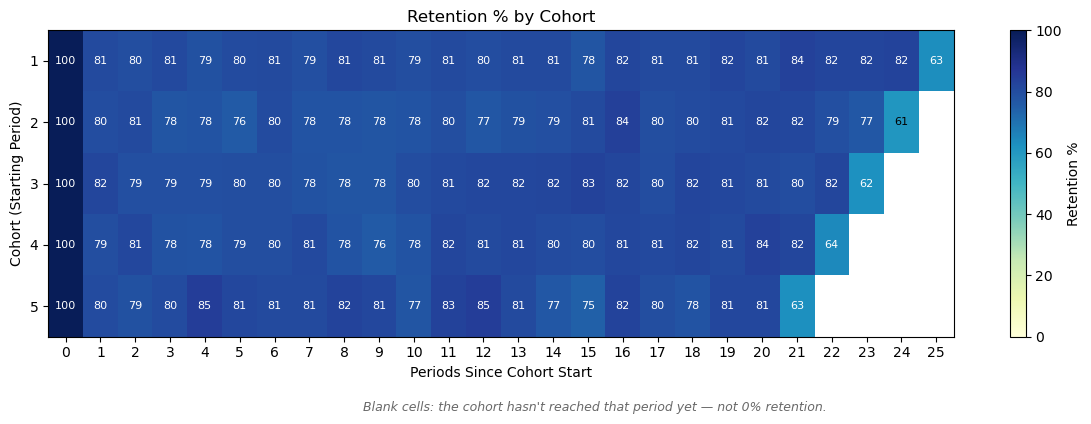

Min/max retention % (periods 1-20, reliable cohorts): 74.6% to 84.7%


In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(retention_pct_reliable, cmap="YlGnBu", aspect="auto", vmin=0, vmax=100)

ax.set_xticks(range(len(retention_pct_reliable.columns)))
ax.set_xticklabels(retention_pct_reliable.columns)
ax.set_yticks(range(len(retention_pct_reliable.index)))
ax.set_yticklabels(retention_pct_reliable.index)
ax.set_xlabel("Periods Since Cohort Start")
ax.set_ylabel("Cohort (Starting Period)")
ax.set_title("Retention % by Cohort")

for i in range(len(retention_pct_reliable.index)):
    for j in range(len(retention_pct_reliable.columns)):
        value = retention_pct_reliable.iloc[i, j]
        if pd.notna(value):
            bg_r, bg_g, bg_b, _ = plt.cm.YlGnBu(value / 100)
            bg_luminance = 0.2126 * bg_r + 0.7152 * bg_g + 0.0722 * bg_b
            text_color = "black" if bg_luminance > 0.5 else "white"
            ax.text(j, i, f"{value:.0f}", ha="center", va="center",
                     color=text_color, fontsize=8)

plt.colorbar(im, ax=ax, label="Retention %")
fig.text(0.5, -0.04,
          "Blank cells: the cohort hasn't reached that period yet — not 0% retention.",
          ha="center", fontsize=9, style="italic", color="dimgray")
plt.tight_layout()

from pathlib import Path
Path("../outputs/figures").mkdir(parents=True, exist_ok=True)
plt.savefig('../outputs/figures/04_retention_cohort.png', bbox_inches='tight', dpi=300)
plt.show()

window = retention_pct_reliable.loc[:, 1:20]
print(f"Min/max retention % (periods 1-20, reliable cohorts): {window.min().min():.1f}% to {window.max().max():.1f}%")

The heatmap makes the core finding visually unambiguous: the share of each cohort that is active holds steady in the 75-85% range across nearly the entire matrix (periods 1 through ~20), regardless of cohort or how many periods have
passed. There's no gradual decay pattern: the share of a cohort active 15 periods
after its start is about the same as 3 periods after. This doesn't mean the same
households are active every period; the matrix counts how many are active, not who.

One pattern stands out, visible as the only lighter-colored block in the
matrix: retention drops to 61-64% in the final column of every cohort row (e.g., cohort 1's period 25 at 63%, cohort 2's period 24 at 61%). This
lines up exactly across all 5 cohorts at their respective final columns,
which is the signature of a **window-edge effect**, not a real behavioral
drop-off: households active near day 711 simply haven't had the chance to
make a purchase in a period that extends past the end of the available
data. This is an artifact of the observation window ending, not evidence
that retention actually declines late in a household's lifecycle.

## 4. Conclusion

This notebook set out to answer: once households start buying, how
consistently do they stay active, and does that differ by when they started?

Cohorts were built on 28-day periods rather than calendar months, chosen
for consistency with the already-validated `WEEK_NO` column rather than
introducing a new, unverified time unit. Cohort sizes turned out to be
heavily front-loaded, periods 1-5 account for the overwhelming majority of
households (2,488 of 2,500), while periods 6 onward each have only 1-4
households, a reflection of most households' first *recorded* purchase
falling early in the data window (left censoring), not of when they were acquired.
This was documented explicitly and the small cohorts excluded from the main
analysis rather than let their noise distort the picture.

Period activity among the 5 reliable cohorts is stable and consistent: 74.6-84.7%
across periods 1-20 (Section 3). The trend check found a small but
statistically significant upward drift over that window, not decay, and
not large enough to be practically meaningful: roughly +0.08 percentage
points per period, about 1.7 points total across all 20 periods, with the
regression explaining only a quarter of the period-to-period variation
(R² = 0.25). "Stable" is still the right summary; "perfectly flat" would
overstate it. No cohort performs notably worse than the others. The one
deviation, a drop to 61-64% in each cohort's final 1-2 columns, was
identified as a window-edge artifact: every cohort's final visible column
falls in the same short, 11-day final period (Section 3), and households
active near the end of the observation period haven't had time to
repurchase within it — not a genuine late-stage retention problem.

The overall picture is a panel of households that keep buying at a steady
rate over two years, with no sign of decay, which contrasts with what a naive
read of "63% at the far edge" might have suggested without the artifact check.
Because dunnhumby is a fixed panel rather than the retailer's whole customer
base, this describes how panel households behave, not the retailer's customer
churn. `04_retention_cohorts.ipynb` is
complete; `05_campaigns_and_coupons.ipynb` examines whether campaigns change
households' spending.